Imports and File path

In [29]:
import time 
import pandas as pd

pd.set_option('display.float_format', "{:.2f}".format)
DATA_PATH = "/mnt/c/Projects/fraud-analytics-project/data/raw/paysim.csv"

In [30]:
import os
os.makedirs("/mnt/c/Projects/fraud-analytics-project/data/processed", exist_ok=True)
df.to_parquet("/mnt/c/Projects/fraud-analytics-project/data/processed/paysim.parquet", index=False)
print("Saved Parquet copy")

Saved Parquet copy


Load the data

In [31]:
import os
PARQUET_PATH = "/mnt/c/Projects/fraud-analytics-project/data/processed/paysim.parquet"

start = time.time()
if os.path.exists(PARQUET_PATH):
    df = pd.read_parquet(PARQUET_PATH, dtype_backend="pyarrow")
else:
    df = pd.read_csv(DATA_PATH, engine="pyarrow", dtype_backend="pyarrow")
print(f"Loaded {len(df):,} rows in {time.time() - start:.1f} seconds")

Loaded 6,362,620 rows in 5.8 seconds


start = time.time()
df = pd.read_csv(DATA_PATH, engine="pyarrow", dtype_backend="pyarrow")
print(f"Loaded in {time.time() - start:.1f} seconds")

size,types and memory

In [32]:
print("Rows:", f"{len(df):,}", "| Columns:", df.shape[1])
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
df.dtypes

Rows: 6,362,620 | Columns: 13
Memory: 774 MB


step               int64[pyarrow]
type              string[pyarrow]
amount            double[pyarrow]
nameOrig          string[pyarrow]
oldbalanceOrg     double[pyarrow]
newbalanceOrig    double[pyarrow]
nameDest          string[pyarrow]
oldbalanceDest    double[pyarrow]
newbalanceDest    double[pyarrow]
isFraud            int64[pyarrow]
isFlaggedFraud     int64[pyarrow]
hour               int64[pyarrow]
day                int64[pyarrow]
dtype: object

In [33]:
df.head(10)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,hour,day
0,1,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.00,0.00,0,0,0,1
1,1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.00,0.00,0,0,0,1
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,0,0,1
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.00,0.00,1,0,0,1
4,1,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.00,0.00,0,0,0,1
5,1,PAYMENT,7817.71,C90045638,53860.00,46042.29,M573487274,0.00,0.00,0,0,0,1
6,1,PAYMENT,7107.77,C154988899,183195.00,176087.23,M408069119,0.00,0.00,0,0,0,1
7,1,PAYMENT,7861.64,C1912850431,176087.23,168225.59,M633326333,0.00,0.00,0,0,0,1
8,1,PAYMENT,4024.36,C1265012928,2671.00,0.00,M1176932104,0.00,0.00,0,0,0,1
9,1,DEBIT,5337.77,C712410124,41720.00,36382.23,C195600860,41898.00,40348.79,0,0,0,1


Missing values and duplicates

In [34]:
print("Missing values per column:")
print(df.isna().sum())
print("\nFully duplicated rows:", f"{df.duplicated().sum():,}")

Missing values per column:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
hour              0
day               0
dtype: int64

Fully duplicated rows: 0


In [35]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
step,6362620.00,<NA>,<NA>,<NA>,243.40,142.33,1.00,156.00,239.00,335.00,743.00
type,6362620,5,CASH_OUT,2237500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,6362620.00,<NA>,<NA>,<NA>,179861.90,603858.23,0.00,13389.57,74871.94,208721.48,92445516.64
nameOrig,6362620,6353307,C2098525306,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceOrg,6362620.00,<NA>,<NA>,<NA>,833883.10,2888242.67,0.00,0.00,14208.00,107315.18,59585040.37
newbalanceOrig,6362620.00,<NA>,<NA>,<NA>,855113.67,2924048.50,0.00,0.00,0.00,144258.41,49585040.37
nameDest,6362620,2722362,C1286084959,113,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceDest,6362620.00,<NA>,<NA>,<NA>,1100701.67,3399180.11,0.00,0.00,132705.66,943036.71,356015889.35
newbalanceDest,6362620.00,<NA>,<NA>,<NA>,1224996.40,3674128.94,0.00,0.00,214661.44,1111909.25,356179278.92
isFraud,6362620.00,<NA>,<NA>,<NA>,0.00,0.04,0.00,0.00,0.00,0.00,1.00


In [36]:
print(df["type"].value_counts(), "\n")
print("Origin prefixes:\n", df["nameOrig"].str[0].value_counts(), "\n")
print("Destination prefixes:\n", df["nameDest"].str[0].value_counts())

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64[pyarrow] 

Origin prefixes:
 nameOrig
C    6362620
Name: count, dtype: int64[pyarrow] 

Destination prefixes:
 nameDest
C    4211125
M    2151495
Name: count, dtype: int64[pyarrow]


In [37]:
fraud = df["isFraud"].sum()
print(f"Fraud rows: {fraud:,} ({fraud / len(df):.4%})")
print(f"Flagged by legacy rule (isFlaggedFraud): {df['isFlaggedFraud'].sum():,}")
print(f"Steps: {df['step'].min()} to {df['step'].max()} ({df['step'].nunique()} distinct)")

Fraud rows: 8,213 (0.1291%)
Flagged by legacy rule (isFlaggedFraud): 16
Steps: 1 to 743 (743 distinct)


## Session 1 findings: data health
- 6,362,620 rows, 11 columns; no missing values; no duplicate rows.
- All origins are customers (C). Destinations: 4,211,125 customers, 2,151,495 merchants (M).
- Merchant destinations equal the PAYMENT count exactly: all payments go to merchants, and only payments do.
- All 743 hourly steps present (1 to 743), so no gaps in the timeline.
- 8,213 fraud rows (0.129%): heavy class imbalance.
- Legacy rule (isFlaggedFraud) flags only 16 rows, catching at most ~0.2% of fraud.

## Fraud Patterns

Fraud patterns

In [38]:
by_type = (
    df.groupby("type")
      .agg(txn_count=("isFraud", "size"), fraud_count=("isFraud", "sum"))
      .assign(fraud_rate_pct=lambda t: t.fraud_count / t.txn_count * 100)
      .sort_values("fraud_count", ascending=False)
)
by_type

,txn_count,fraud_count,fraud_rate_pct
type,,,
CASH_OUT,2237500,4116,0.18
TRANSFER,532909,4097,0.77
CASH_IN,1399284,0,0.00
DEBIT,41432,0,0.00
PAYMENT,2151495,0,0.00


**Fraud by type:** fraud occurs only in TRANSFER (4,097; 0.77% of transfers) and CASH_OUT (4,116; 0.18%). CASH_IN, DEBIT and PAYMENT have zero fraud. The near-equal counts reflect the fraud pattern: transfer to a mule account, then cash out.

fraud rate within the eligible types

In [39]:
elig = df[df["type"].isin(["TRANSFER", "CASH_OUT"])]
print(f"Eligible rows: {len(elig):,}")
print(f"Fraud rate within TRANSFER + CASH_OUT: {elig['isFraud'].mean():.4%}")

Eligible rows: 2,770,409
Fraud rate within TRANSFER + CASH_OUT: 0.2965%


**Eligible types:** 2,770,409 TRANSFER + CASH_OUT rows (44% of data); fraud rate within them is 0.30% (1 in ~337), versus 0.13% overall. This is the headline rate for the dashboard.

## Fraud by hour of the day and by day

In [40]:
step = df["step"].astype("int64")
df["hour"] = (step - 1) % 24
df["day"] = (step - 1) // 24 + 1

by_hour = df.groupby("hour").agg(txn=("isFraud", "size"), fraud=("isFraud", "sum"))
by_hour["fraud_rate_pct"] = by_hour["fraud"] / by_hour["txn"] * 100

by_day = df.groupby("day").agg(txn=("isFraud", "size"), fraud=("isFraud", "sum"))

by_hour

,txn,fraud,fraud_rate_pct
hour,,,
0,27111,358,1.32
1,9018,372,4.13
2,2007,326,16.24
3,1241,274,22.08
4,1641,366,22.30
5,3420,358,10.47
6,8988,328,3.65
7,26915,368,1.37
8,283518,341,0.12


**Hour of day:** fraud count is flat (~300–375 per hour) while legitimate volume drops sharply at night, so the fraud rate rises from 0.05–0.12% in the daytime to 16–22% between 02:00 and 04:00. Hour is a strong signal, partly a simulation artefact (fraud generated uniformly in time). Hour 0 assumes step 1 = midnight.

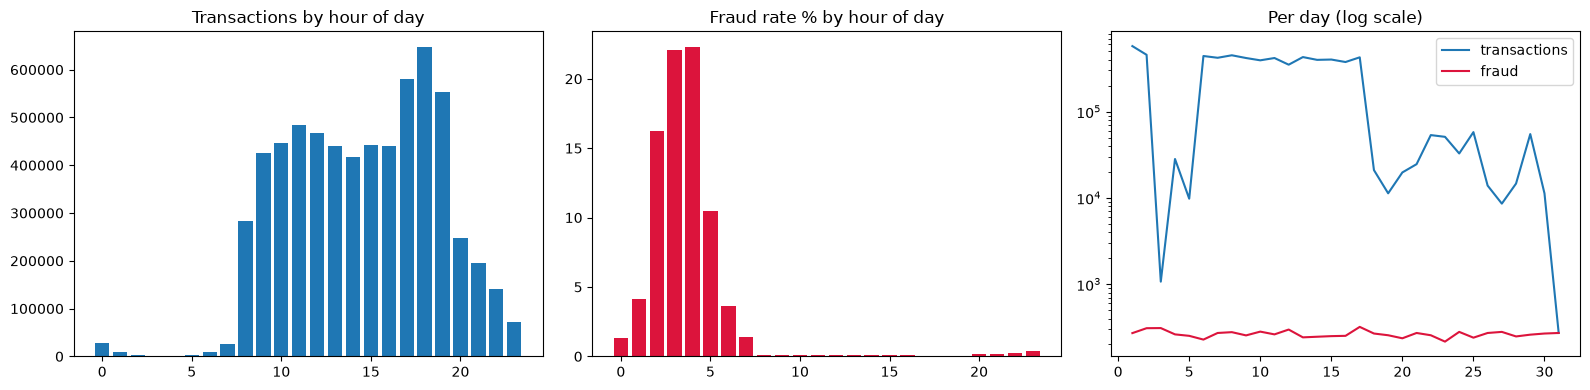

In [41]:
# charts of the pattern
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].bar(by_hour.index, by_hour["txn"].to_numpy())
axes[0].set_title("Transactions by hour of day")

axes[1].bar(by_hour.index, by_hour["fraud_rate_pct"].to_numpy(), color="crimson")
axes[1].set_title("Fraud rate % by hour of day")

axes[2].plot(by_day.index, by_day["txn"].to_numpy(), label="transactions")
axes[2].plot(by_day.index, by_day["fraud"].to_numpy(), color="crimson", label="fraud")
axes[2].set_yscale("log")
axes[2].set_title("Per day (log scale)")
axes[2].legend()

plt.tight_layout()
plt.show()

**By day:** fraud is steady at ~250–300 per day all month, but legitimate volume varies hugely: ~400–500k/day on days 1–2 and 6–17, a dip on days 3–5, and only ~10–60k/day on days 18–30. Day 31 is partial (23 hours). The fraud rate therefore rises sharply after day 17 (a simulation artefact). The streaming slice (days 30–31) is small (~10–15k events) with a high fraud rate.

isFraud           0           1
count    2762196.00     8213.00
mean      314115.50  1467967.30
std       877144.15  2404252.95
min            0.01        0.00
50%       171034.46   441423.44
90%       540837.92  4521723.51
99%      2580263.92 10000000.00
max     92445516.64 10000000.00


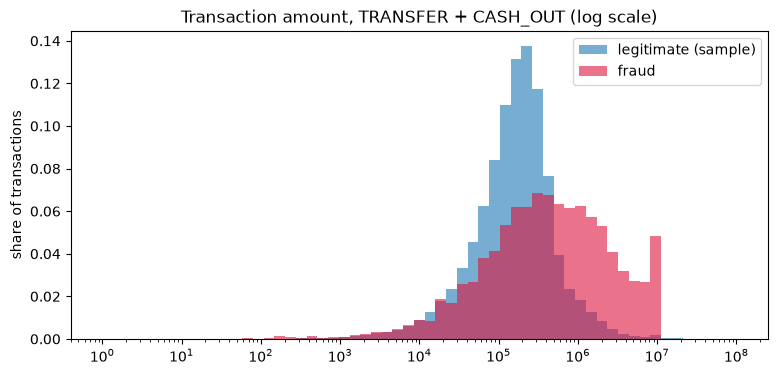

In [42]:
## : amounts, fraud vs legitimate
import numpy as np

print(elig.groupby("isFraud")["amount"].describe(percentiles=[0.5, 0.9, 0.99]).T)

fraud_w = np.ones_like(fraud_amt) / len(fraud_amt)
legit_w = np.ones_like(legit_amt) / len(legit_amt)

plt.figure(figsize=(9, 4))
plt.hist(legit_amt, bins=bins, weights=legit_w, alpha=0.6, label="legitimate (sample)")
plt.hist(fraud_amt, bins=bins, weights=fraud_w, alpha=0.6, color="crimson", label="fraud")
plt.xscale("log")
plt.ylabel("share of transactions")
plt.title("Transaction amount, TRANSFER + CASH_OUT (log scale)")
plt.legend()
plt.show()

**Amount percentiles:** median fraud 441k vs 171k legitimate (~2.6×); 90th percentile 4.52M vs 541k. Fraud's 99th percentile and max are both exactly 10,000,000, confirming a 10M cap; legitimate goes up to 92M. A threshold at the legitimate 99th percentile (~2.6M) flags ~1% of legitimate transactions. Some fraud rows have amount 0.00, to investigate.

**Amounts (TRANSFER + CASH_OUT):** legitimate amounts cluster at ~50k–500k (peak ~200k). Fraud skews larger, with a large share at 1M–10M and a spike at exactly 10M with nothing above, suggesting a 10M cap per fraud transaction. Overlap below 1M means amount alone is not enough. (Shares plotted with per-group weights; density=True on log bins was misleading.)

In [43]:
## Does fraud empty the origin account

drained = (elig["oldbalanceOrg"] > 0) & (elig["newbalanceOrig"] == 0)
full_amount = (elig["amount"] - elig["oldbalanceOrg"]).abs() < 0.01

summary = pd.DataFrame({
    "drained_to_zero_pct": drained.groupby(elig["isFraud"]).mean() * 100,
    "amount_equals_full_balance_pct": full_amount.groupby(elig["isFraud"]).mean() * 100,
})
summary

,drained_to_zero_pct,amount_equals_full_balance_pct
isFraud,,
0,42.72,0.00
1,97.55,97.82


**Account draining:** 97.6% of fraud empties the origin account, but so do 42.7% of legitimate TRANSFER/CASH_OUT rows (weak signal alone). Sending exactly the full balance occurs in 97.8% of fraud vs ~0% of legitimate: the strongest signal found, likely a simulation artefact. The small gap between the two explains the 0.00-amount frauds: attempts on already-empty accounts.

In [44]:
pd.crosstab(full_amount, elig["isFraud"], margins=True)

isFraud,0,1,All
row_0,,,
False,2762196,179,2762375
True,0,8034,8034
All,2762196,8213,2770409


**Rule check, amount = full balance:** flags 8,034 rows, all fraud (precision 100%), and misses 179 of 8,213 frauds (recall 97.8%). Legacy rule flags 16. Hypothesis: the 179 misses are capped at 10M because the balance exceeded 10M.

In [45]:
fraud_rows = elig[elig["isFraud"] == 1]
missed = fraud_rows[~full_amount[elig["isFraud"] == 1]]

print(f"Fraud rows at exactly 10,000,000: {(fraud_rows['amount'] == 10_000_000).sum():,}")
print(f"Fraud rows with amount 0: {(fraud_rows['amount'] == 0).sum():,}")
print(f"\nMissed frauds: {len(missed):,}")
print(f"  ...of which amount is exactly 10M: {(missed['amount'] == 10_000_000).sum():,}")
print(f"  ...of which starting balance was over 10M: {(missed['oldbalanceOrg'] > 10_000_000).sum():,}")
missed[["step", "type", "amount", "oldbalanceOrg", "newbalanceOrig"]].head(10)

Fraud rows at exactly 10,000,000: 287
Fraud rows with amount 0: 16

Missed frauds: 179
  ...of which amount is exactly 10M: 145
  ...of which starting balance was over 10M: 148


,step,type,amount,oldbalanceOrg,newbalanceOrig
724,1,CASH_OUT,416001.33,0.00,0.00
1911,1,CASH_OUT,132842.64,4499.08,0.00
4440,4,TRANSFER,10000000.00,12930418.44,2930418.44
14861,8,CASH_OUT,181728.11,0.00,0.00
25875,8,TRANSFER,1078013.76,0.00,0.00
60853,9,TRANSFER,994453.20,1437370.87,442917.67
77745,10,CASH_OUT,277970.88,0.00,0.00
138559,11,TRANSFER,1933920.80,0.00,0.00
169998,12,CASH_OUT,149668.66,0.00,0.00
178668,12,CASH_OUT,222048.71,0.00,0.00


**10M cap:** 287 frauds are exactly 10,000,000; 16 frauds are 0.00 (attempts on empty accounts).
**The 179 frauds missed by "amount = full balance":** 145 are exactly 10M from accounts holding >10M (cap explains ~81%). The remaining ~31 involve inconsistent balances (amount sent from a zero balance, amount larger than the balance) or partial theft.
**Rule v1 (to validate in Session 3):** flag TRANSFER/CASH_OUT if amount = full balance, OR amount = 10M and starting balance > 10M. Expected recall ~99.6%.

## session 3: rule validation,balance checks and summary

In [47]:
## validate rule v1

cap_rule = (elig["amount"] == 10_000_000) & (elig["oldbalanceOrg"] > 10_000_000)
rule_v1 = full_amount | cap_rule

tp = (rule_v1 & (elig["isFraud"] == 1)).sum()
fp = (rule_v1 & (elig["isFraud"] == 0)).sum()
fn = (~rule_v1 & (elig["isFraud"] == 1)).sum()

print(pd.crosstab(rule_v1, elig["isFraud"], margins=True))
print(f"\nPrecision: {tp / (tp + fp):.2%}  (of flagged transactions, share that are fraud)")
print(f"Recall:    {tp / (tp + fn):.2%}  (of all fraud, share the rule catches)")
print(f"Legacy rule recall: {elig.loc[elig['isFraud'] == 1, 'isFlaggedFraud'].sum() / (tp + fn):.2%}")

isFraud        0     1      All
row_0                          
False    2762196    34  2762230
True           0  8179     8179
All      2762196  8213  2770409

Precision: 100.00%  (of flagged transactions, share that are fraud)
Recall:    99.59%  (of all fraud, share the rule catches)
Legacy rule recall: 0.19%


**Rule v1 validated:** flag TRANSFER/CASH_OUT if amount = full balance OR (amount = 10M AND starting balance > 10M). Precision 100% (0 false positives in 2.76M legitimate rows); recall 99.59% (8,179 of 8,213; 34 missed). Legacy rule recall: 0.19%. Near-perfect results reflect simulated fraud behaviour; a real deployment would need more signals and monitoring.

In [48]:
## Do the balances add up

orig_error = (elig["oldbalanceOrg"] - elig["amount"] - elig["newbalanceOrig"]).abs() > 0.01
dest_error = (elig["oldbalanceDest"] + elig["amount"] - elig["newbalanceDest"]).abs() > 0.01
dest_both_zero = (elig["oldbalanceDest"] == 0) & (elig["newbalanceDest"] == 0) & (elig["amount"] > 0)

balance_check = pd.DataFrame({
    "orig_mismatch_pct": orig_error.groupby(elig["isFraud"]).mean() * 100,
    "dest_mismatch_pct": dest_error.groupby(elig["isFraud"]).mean() * 100,
    "dest_zero_before_and_after_pct": dest_both_zero.groupby(elig["isFraud"]).mean() * 100,
})
balance_check

,orig_mismatch_pct,dest_mismatch_pct,dest_zero_before_and_after_pct
isFraud,,,
0,90.51,22.58,0.06
1,0.55,56.50,49.56


**Balance reconciliation (TRANSFER/CASH_OUT):** origin balances fail to reconcile for 90.5% of legitimate rows but only 0.55% of fraud, a simulation property rather than a quality failure, so no alert on it. Destination mismatch: 22.6% legitimate vs 56.5% fraud. Destination balance 0 before and after despite money arriving: 0.06% legitimate (~1,650 rows) vs 49.6% fraud (likely untracked mule accounts). Design changes: keep balance-error columns as soft flags without alerting; add `dest_balance_unchanged` as a candidate rule v2 signal.

In [49]:
## Do merchants have balance data

payments = df[df["type"] == "PAYMENT"]
merchant_zero = (payments["oldbalanceDest"] == 0) & (payments["newbalanceDest"] == 0)

print(f"PAYMENT rows: {len(payments):,}")
print(f"Merchant balances 0 before and after: {merchant_zero.mean():.2%}")

PAYMENT rows: 2,151,495
Merchant balances 0 before and after: 100.00%


**Merchant balances:** all 2,151,495 PAYMENT rows have merchant destination balances of 0 before and after (100%). Merchants carry no balance data; silver sets them to null and skips balance checks.

## Summary of findings

**Data health**
- 6,362,620 rows, 11 columns, no missing values, no duplicates. 743 hourly steps, no gaps; no real dates (silver derives `event_ts` from an anchor date).

**Where fraud happens**
- 8,213 fraud rows (0.129% overall). Fraud occurs only in TRANSFER (0.77%) and CASH_OUT (0.18%), 0.30% within those two types.
- Near-equal fraud counts in TRANSFER (4,097) and CASH_OUT (4,116) reflect the pattern: transfer to a mule account, then cash out.

**When**
- Fraud arrives at a constant rate (~300-375 per hour, ~250-300 per day), while legitimate volume follows daily and monthly cycles. The fraud rate therefore peaks at 16-22% between 02:00 and 04:00 and rises sharply after day 17 (simulation artefact). Day 31 is partial.

**How**
- Fraud amounts are larger (median 441k vs 171k) and capped at exactly 10,000,000.
- 97.8% of fraud sends exactly the full starting balance; legitimate transactions never do.
- 49.6% of fraud goes to receivers whose balance stays 0 before and after (0.06% of legitimate).

**Data quirks**
- Origin balances fail to reconcile for 90.5% of legitimate TRANSFER/CASH_OUT rows (simulation property, not a quality failure).
- Merchant balances are always 0 (no data). 16 frauds have amount 0 (attempts on empty accounts).

**Detection**
- Legacy rule (`isFlaggedFraud`): 16 flags, 0.19% recall.
- Rule v1 (amount = full balance, OR amount = 10M with balance > 10M): precision 100%, recall 99.59%, 34 frauds missed.
- Caveat: near-perfect results reflect simulated behaviour; real data would need more signals.

**Design changes from this EDA**
1. `dim_transaction_type.is_fraud_eligible` = TRANSFER, CASH_OUT; the headline fraud rate is measured within these.
2. Silver rule = rule v1; add `amount_is_full_balance` and `dest_balance_unchanged` columns.
3. Balance-error columns stay soft flags with no alerting (90% legitimate mismatch is expected).
4. Merchant destination balances set to null.
5. Streaming slice (days 30-31) is small (~10-15k events) with a high fraud rate; label the difference on the pipeline health page.
6. Dashboard uses rates, not counts, and notes that time-based patterns are simulation artefacts.